In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
df=pd.read_csv('vehicle_fuel.csv')
print("Data loaded successfully!")
print("Data shape:", df.shape)
display(df.head())
df.info()

Data loaded successfully!
Data shape: (320, 9)


,fuel_eff,cylinders,engine_size,horsepower,weight,acceleration,model_year,origin,car_name
0,8.3,8,6000,284,1739,16.7,2011,1,ford explorer
1,18.6,4,1740,94,1055,18.7,2019,2,bmw 520i
2,12.5,6,2800,141,1370,18.6,2021,1,buick lacrosse
3,10.3,8,4430,203,1635,19.2,2015,1,dodge dart
4,15.7,6,2790,129,1183,15.4,2021,1,chevrolet tahoe


<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fuel_eff      320 non-null    float64
 1   cylinders     320 non-null    int64  
 2   engine_size   320 non-null    int64  
 3   horsepower    320 non-null    str    
 4   weight        320 non-null    int64  
 5   acceleration  320 non-null    float64
 6   model_year    320 non-null    int64  
 7   origin        320 non-null    int64  
 8   car_name      320 non-null    str    
dtypes: float64(2), int64(5), str(2)
memory usage: 22.6 KB


cleaning data

In [3]:

# Find question marks in all columns
question_marks = df.astype("string").apply(
    lambda col: col.str.strip().eq("?").sum()
)

print("Question marks in each column:")
display(question_marks[question_marks > 0])

print("Total question marks in dataset:", question_marks.sum())


Question marks in each column:


horsepower    7
dtype: int64

Total question marks in dataset: 7


In [4]:
df["horsepower"] = pd.to_numeric(df["horsepower"], errors="coerce")
df.info()
df["horsepower"].isna().sum()

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   fuel_eff      320 non-null    float64
 1   cylinders     320 non-null    int64  
 2   engine_size   320 non-null    int64  
 3   horsepower    313 non-null    float64
 4   weight        320 non-null    int64  
 5   acceleration  320 non-null    float64
 6   model_year    320 non-null    int64  
 7   origin        320 non-null    int64  
 8   car_name      320 non-null    str    
dtypes: float64(3), int64(5), str(1)
memory usage: 22.6 KB


np.int64(7)

**Question 1 – Central Tendency**
Before building any model, your team lead asks: “Which numeric attributes can we safely summarise
by their average, and which ones should we look at more closely before modelling?” Answer by
comparing two measures of central tendency, the mean and the median, for every numeric attribute
(i.e. all attributes except car_name).

(a) Your team lead wants to compare all numeric attributes at a glance. Produce ONE compact 
summary that, for every numeric attribute, shows both measures, how far apart they are in 
relative terms, and a verdict. Measure the distance as Deviation = |mean − median| / mean × 
100, and label an attribute “High” if its deviation is above 10 % and “Low” otherwise.

In [5]:
values = df.select_dtypes("number")
summary = pd.DataFrame({
    "mean": values.mean(),
    "median": values.median()
})
summary["deviation"] = (summary["mean"] - summary["median"]).abs() / summary["mean"] * 100
summary["label"] = np.where(summary["deviation"] > 10, "High", "Low")
summary. round(2)

,mean,median,deviation,label
fuel_eff,13.39,14.0,4.53,Low
cylinders,5.34,4.0,25.15,High
engine_size,2985.53,2320.0,22.29,High
horsepower,150.07,121.0,19.37,High
weight,1333.10,1238.0,7.13,Low
acceleration,17.52,17.6,0.47,Low
model_year,2016.07,2016.0,0.00,Low
origin,1.63,1.0,38.58,High


**================================================================================================================================================**

(b) List the attributes that need further investigation. For these attributes, explain what it 
suggests about the data when the mean is clearly larger than the median. 

,mean,median,deviation,label
cylinders,5.343750,4.0,25.146199,High
engine_size,2985.531250,2320.0,22.291887,High
horsepower,150.070288,121.0,19.371115,High
origin,1.628125,1.0,38.579655,High


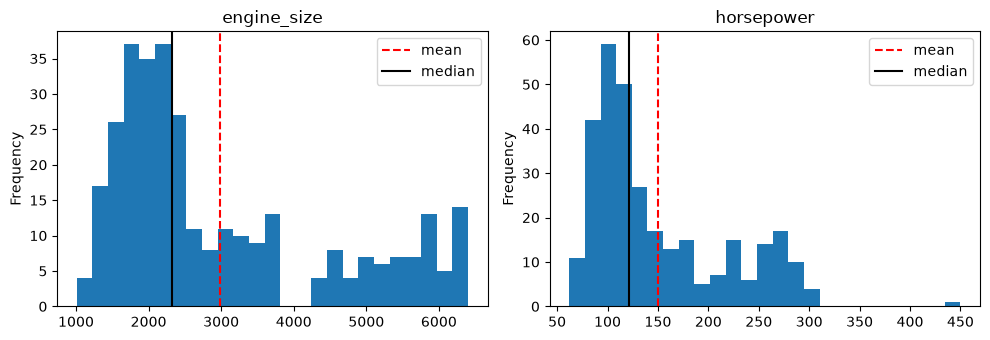

In [25]:
display(summary[summary["label"] == "High"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))

df["engine_size"].plot.hist(bins=25, ax=ax[0], title="engine_size", label = "_nolegend_")
ax[0].axvline(df["engine_size"].mean(), color="red", linestyle="--", label="mean")
ax[0].axvline(df["engine_size"].median(), color="black", linestyle="-", label="median")
ax[0].legend()

df["horsepower"].plot.hist(bins=25, ax=ax[1], title="horsepower", label = "_nolegend_")
ax[1].axvline(df["horsepower"].mean(), color="red", linestyle="--", label="mean")
ax[1].axvline(df["horsepower"].median(), color="black", linestyle="-", label="median")
ax[1].legend()

plt.tight_layout()
plt.show()

THE MEAN IS CLEARLY LARGER THAN THE MEDIAN (E.G, "horsepower" MEAN = 150.07 & MEDIAN = 121.0)
Based on this:
- The mean is affected by large values, but the median is not.
- When the mean is clearly larger than the median, it means there are large values pulling it upwards.
- This suggests the distribution is right-skewed (most values are small or medium, with a tail of large values), and it may contain outliers.
- So the mean alone does not represent the typical value well.
- We need to examine these attributes ( "cylinders", "engine_size", "horsepower", and "origin") before modelling.
- The histograms of `engine_size` and `horsepower` show most values on the left and a long tail on the right. This confirms the right skew.

**================================================================================================================================================**

(c) If any attribute cannot be summarised as expected, find out why. Report the cause, the 
number of records affected, and what you did so that its mean and median could be 
calculated. 

In [7]:
print("Missing horsepower after conversion:", df["horsepower"].isna().sum())
print("Valid values used:", df["horsepower"].notna().sum())
df[df["horsepower"].isna()]

Missing horsepower after conversion: 7
Valid values used: 313


,fuel_eff,cylinders,engine_size,horsepower,weight,acceleration,model_year,origin,car_name
8,14.5,5,2460,NaN,1298,18.1,2018,2,bmw 520i
63,19.4,4,1810,NaN,1048,16.1,2022,1,chevrolet cruze
129,11.0,6,3260,NaN,1404,15.9,2013,1,ford explorer
188,18.1,4,2280,NaN,1090,18.0,2013,2,volvo s60
241,15.0,4,2050,NaN,1253,17.7,2022,3,honda jazz
297,9.9,8,5840,NaN,1739,17.3,2017,1,buick enclave
313,15.7,4,1900,NaN,1085,19.5,2011,3,toyota corolla


**horsepower**
- **Cause:** "horsepower" was stored as text (string), not as numbers, because some values were the symbol "?".
- **Records affected:** 7 records (out of 320).
- **What I did:** I converted the column to numbers with "pd.to_numeric(errors="coerce")", so each "?" became "NaN" (Not a Number, i.e. a missing value).
- I did not delete the 7 rows, because their other attributes are valid and are needed later.
- The mean and median ignore "NaN", so they were calculated from the remaining 313 values.

**================================================================================================================================================**

(d) Two of the flagged attributes take only a handful of distinct values. Which are they, and is their 
high deviation more likely caused by errors in the data or by the way their values are 
distributed? Justify briefly. 

In [8]:
flagged = ['fuel_eff', 'cylinders', 'engine_size', 'horsepower', 'weight', 'acceleration', 'model_year', 'origin']
print(df[flagged].nunique())

fuel_eff        133
cylinders         5
engine_size     211
horsepower      156
weight          254
acceleration     82
model_year       13
origin            3
dtype: int64


In [9]:
print(df["cylinders"].value_counts().sort_index())
print("Mean:", df["cylinders"].mean().round(2))
print("Median:", df["cylinders"].median())
print("=="*10)
print(df["origin"].value_counts().sort_index())
print("Mean:", df["origin"].mean().round(2)) 
print ("Median:",df["origin"].median())

cylinders
3      4
4    170
5      8
6     63
8     75
Name: count, dtype: int64
Mean: 5.34
Median: 4.0
origin
1    190
2     59
3     71
Name: count, dtype: int64
Mean: 1.63
Median: 1.0


The two attributes are "cylinders" (values 3, 4, 5, 6, and 8) and "origin" (values 1, 2, and 3).

Their high deviation is more likely caused by **the way their values are distributed**, not by errors in the data:

- All values are valid according to the dataset description. Cylinder counts of 3, 4, 5, 6, and 8 are present, and "origin" uses the codes of areas  1, 2, and 3 from the data dictionary.
- "cylinders": After sorting the 320 values, the 160th and 161st values are both 4, so the median is 4. The 138 vehicles with 6 or 8 cylinders pull the mean up to 5.34.
- "origin": After sorting the 320 values, the 160th and 161st values are both 1, so the median is 1. Codes 2 and 3 pull the mean up to 1.63.
- "origin" is a category code, so its mean has no meaningful interpretation.

**================================================================================================================================================**

**Question 2 – Box Plots and Outliers**
Draw Tukey box plots (whiskers extend to the furthest data value within 1.5 × IQR of the box) for
only these three attributes: engine_size, acceleration, and origin. Answer the following by
investigating the box plots.

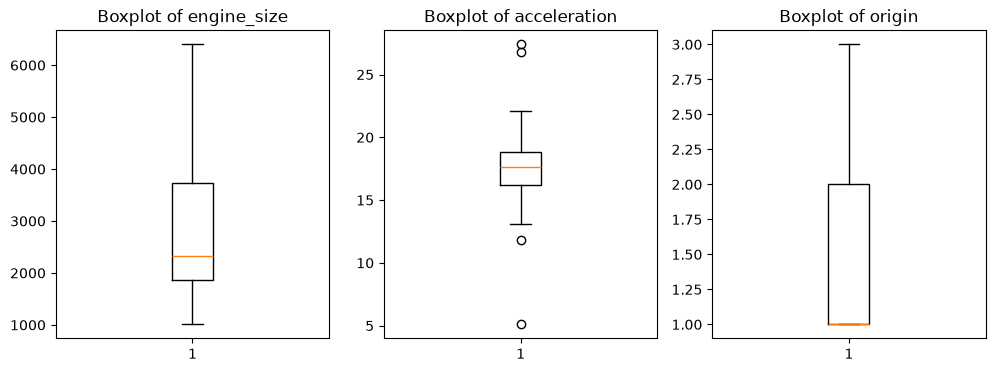

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["engine_size", "acceleration", "origin"]):
    ax.boxplot(df[col])
    ax.set_title(f"Boxplot of {col}")


### Part A – acceleration


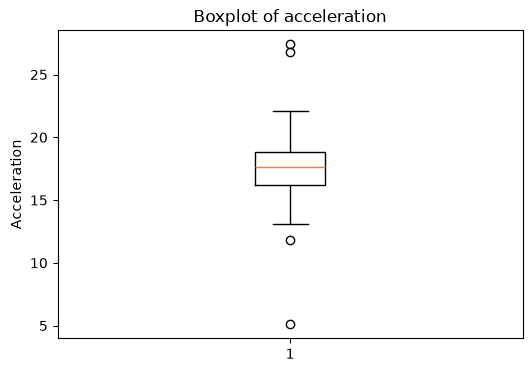

In [11]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["acceleration"])
plt.title("Boxplot of acceleration")
plt.ylabel("Acceleration")
plt.show()

In [12]:
col = "acceleration"

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 =", round(Q1, 2), "| Q3 =", round(Q3, 2), "| IQR =", round(IQR, 2))
print("lower limit =", round(lower_bound, 2), "| upper limit =", round(upper_bound, 2))

lower_outliers = df[df[col] < lower_bound]
upper_outliers = df[df[col] > upper_bound]

print("Outliers below:", len(lower_outliers))
print("Outliers above:", len(upper_outliers))

Q1 = 16.2 | Q3 = 18.82 | IQR = 2.62
lower limit = 12.26 | upper limit = 22.76
Outliers below: 2
Outliers above: 2


**(a) Does the box plot show outliers? How many lie above the upper whisker and how many below the lower whisker?**

Yes, the box plot of "acceleration" shows outliers.

- **Above the upper whisker:** 2 outliers (upper limit = 22.76)
- **Below the lower whisker:** 2 outliers (lower limit = 12.26)
- **Total:** 4 outliers

The limits come from Q1 = 16.2, Q3 = 18.82 and IQR = 2.62

**================================================================================================================================================**

**(b) Identify the vehicles (car_name) behind these outliers. Using their other attributes, decide whether each one is a natural outlier or a likely recording error, and state whether it should be amended.**

In [13]:
cols = ["car_name", "acceleration", "horsepower", "cylinders",
        "engine_size", "weight", "fuel_eff", "model_year", "origin"]

print("Below the lower whisker:")
display(lower_outliers[cols])

print("Above the upper whisker:")
display(upper_outliers[cols])



Below the lower whisker:


,car_name,acceleration,horsepower,cylinders,engine_size,weight,fuel_eff,model_year,origin
14,dodge charger,11.8,278.0,8,6210,1852,6.5,2015,1
110,chevrolet corvette,5.1,450.0,8,6200,1780,8.9,2015,1


Above the upper whisker:


,car_name,acceleration,horsepower,cylinders,engine_size,weight,fuel_eff,model_year,origin
45,nissan micra diesel,27.4,65.0,4,1460,1000,19.5,2017,3
203,volkswagen polo tdi,26.8,75.0,4,1420,1080,18.9,2020,2


**Below the lower whisker (very fast cars):**

- **chevrolet corvette** (acceleration = 5.1 s, horsepower = 450, engine_size = 6200): it has the highest horsepower in the data and a very big engine, so a very fast 0-100 time makes sense. This is a **natural outlier**.
- **dodge charger** (acceleration = 11.8 s, horsepower = 278, 8 cylinders): it is a powerful car, so it is quick. This is a **natural outlier**.


**Above the upper whisker (very slow cars):**

- **nissan micra diesel** (acceleration = 27.4 s, horsepower = 65, engine_size = 1460): it is a small and light diesel car with very low power, so it is slow. This is a **natural outlier**.
- **volkswagen polo tdi** (acceleration = 26.8 s, horsepower = 75, engine_size = 1420): it is a small and light diesel car with low power, so it is slow. This is a **natural outlier**.


**Conclusion:** All four values match the other attributes of each car (power and engine size), so none of them looks like a recording error. **None of them should be amended.**

**================================================================================================================================================**

**(c) In Question 1, acceleration had one of the smallest mean–median deviations. Explain how an attribute with such a small deviation can still contain outliers. What does this tell you about relying on mean vs. median alone?**

In [14]:
print("With outliers   : mean =", round(df[col].mean(), 2), "| median =", df[col].median())

clean = df[(df[col] >= lower_bound) & (df[col] <= upper_bound)][col]
print("Without outliers: mean =", round(clean.mean(), 2), "| median =", clean.median())

outliers = pd.concat([lower_outliers, upper_outliers])
print(outliers[["car_name", col]].assign(diff_from_median=outliers[col] - df[col].median()))
print("Sum of differences:", round((outliers[col] - df[col].median()).sum(), 2))

With outliers   : mean = 17.52 | median = 17.6
Without outliers: mean = 17.52 | median = 17.6
                car_name  acceleration  diff_from_median
14         dodge charger          11.8              -5.8
110   chevrolet corvette           5.1             -12.5
45   nissan micra diesel          27.4               9.8
203  volkswagen polo tdi          26.8               9.2
Sum of differences: 0.7


**The deviation of "acceleration" is small (0.47%), but there are still 4 outliers.**

**Why?**

- Two outliers are very low (5.1 and 11.8).
- Two outliers are very high (26.8 and 27.4).
- Low values pull the mean down. High values pull the mean up.
- They cancel each other, so the mean stays close to the median.
- The mean (17.52) and median (17.6) are the same with and without the outliers.

**Conclusion:**

- A small deviation does not mean there are no outliers.
- The mean and median only show the center, not the extreme values.
- So we should not trust them alone. We should also look at the box plot.

**================================================================================================================================================**

### Part B – engine_size


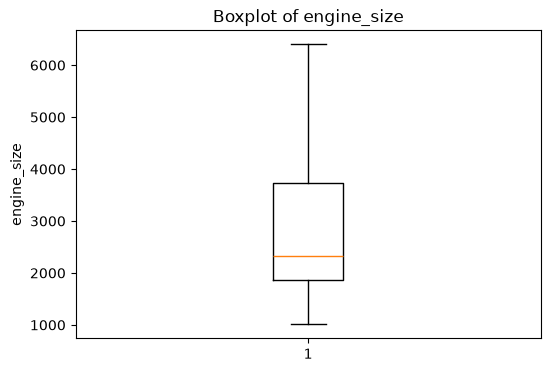

In [15]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["engine_size"])
plt.title("Boxplot of engine_size")
plt.ylabel("engine_size")
plt.show()

**(a) Are there any outliers? Describe the position of the median band inside the box and compare the lengths of the lower and upper whiskers.**

In [16]:
col = "engine_size"

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 =", round(Q1, 2), "| Q3 =", round(Q3, 2), "| IQR =", round(IQR, 2))
print("lower limit =", round(lower_bound, 2), "| upper limit =", round(upper_bound, 2))

lower_outliers = df[df[col] < lower_bound]
upper_outliers = df[df[col] > upper_bound]

print("Outliers below:", len(lower_outliers))
print("Outliers above:", len(upper_outliers))

median = df[col].median()

low_whisker = df[df[col] >= lower_bound][col].min()
up_whisker = df[df[col] <= upper_bound][col].max()

print("Median =", median)
print("Median - Q1 =", median - Q1, "| Q3 - Median =", Q3 - median)

print("Lower whisker ends at:", low_whisker, "| length =", Q1 - low_whisker)
print("Upper whisker ends at:", up_whisker, "| length =", up_whisker - Q3)

Q1 = 1857.5 | Q3 = 3730.0 | IQR = 1872.5
lower limit = -951.25 | upper limit = 6538.75
Outliers below: 0
Outliers above: 0
Median = 2320.0
Median - Q1 = 462.5 | Q3 - Median = 1410.0
Lower whisker ends at: 1010 | length = 847.5
Upper whisker ends at: 6400 | length = 2670.0


**Outliers:** There are no outliers below or above. All values are inside the limits (-951.25 and 6538.75).

**Median position:**

- The median (2320) is close to the bottom of the box.
- Median - Q1 = 462.5, but Q3 - Median = 1410.

**Whiskers:**

- The lower whisker is short (length = 847.5).
- The upper whisker is much longer (length = 2670)

This means the distribution is right-skewed: most engines are small, and a few engines are very big.

**================================================================================================================================================**

**(b) Express the length of each whisker as a percentage of its maximum permissible length (1.5 × IQR), as done in Section 2.4.2.1.3 of the chapter.**

In [17]:
max_len = 1.5 * IQR

lower_len = Q1 - low_whisker
upper_len = up_whisker - Q3

print("Max permissible length =", max_len)
print("Lower whisker:", lower_len, "->", round(lower_len / max_len * 100, 1), "% of max")
print("Upper whisker:", upper_len, "->", round(upper_len / max_len * 100, 1), "% of max")

Max permissible length = 2808.75
Lower whisker: 847.5 -> 30.2 % of max
Upper whisker: 2670.0 -> 95.1 % of max


**Max permissible length = 2808.75**

- The lower whisker uses only about **30.2%** of its maximum length.
- The upper whisker uses about **95.1%** of its maximum length, so it is almost as long as allowed.
- This shows the right tail is much longer than the left tail.

**================================================================================================================================================**

**(c) In Question 1, engine_size was flagged “High”. Based on its box plot, is that caused by outliers or by something else? Explain.**

In [18]:
print("Mean   =", round(df[col].mean(), 1))
print("Median =", df[col].median())
print("Deviation =", round(abs(df[col].mean() - df[col].median()) / df[col].mean() * 100, 2), "%")

print("Number of outliers =", len(lower_outliers) + len(upper_outliers))

print("Skewness =", round(df[col].skew(), 2))

Mean   = 2985.5
Median = 2320.0
Deviation = 22.29 %
Number of outliers = 0
Skewness = 0.95


The high deviation **(22.29%)** is **not** caused by outliers. The box plot shows 0 outliers.

It is caused by the **shape of the distribution**, which is **right-skewed** (mean > median):

- The median **(2320)** is close to the bottom of the box.
- The upper whisker is much longer than the lower whisker (95.1% vs 30.2% of the maximum length).
- Most engines are small, but there is a long tail of big engines (up to 6400 cc). These big values are real and close together, not extreme points.
- They pull the mean up **(2985.5)** above the median **(2320)**.
- The skewness is **0.95**, a positive value, which confirms the right skew.

**================================================================================================================================================**

### Part C – origin

**(a) The box plot of origin looks unusual. Describe exactly what is unusual about the median band and the whiskers.**

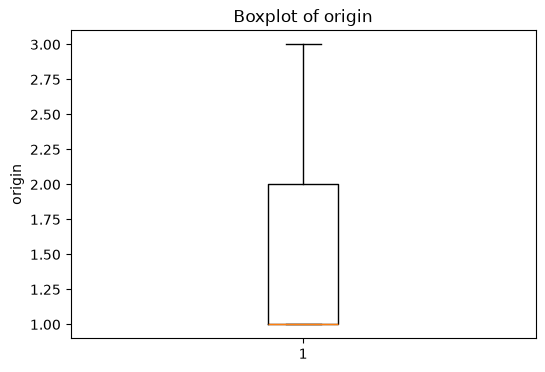

In [19]:
plt.figure(figsize=(6, 4))
plt.boxplot(df["origin"])
plt.title("Boxplot of origin")
plt.ylabel("origin")
plt.show()

In [20]:
col = "origin"

Q1 = df[col].quantile(0.25)
Q3 = df[col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print("Q1 =", round(Q1, 2), "| Q3 =", round(Q3, 2), "| IQR =", round(IQR, 2))
print("lower limit =", round(lower_bound, 2), "| upper limit =", round(upper_bound, 2))

lower_outliers = df[df[col] < lower_bound]
upper_outliers = df[df[col] > upper_bound]

print("Outliers below:", len(lower_outliers))
print("Outliers above:", len(upper_outliers))

median = df[col].median()

low_whisker = df[df[col] >= lower_bound][col].min()
up_whisker = df[df[col] <= upper_bound][col].max()

print("Median =", median)
print("Median - Q1 =", median - Q1, "| Q3 - Median =", Q3 - median)

print("Lower whisker ends at:", low_whisker, "| length =", Q1 - low_whisker)
print("Upper whisker ends at:", up_whisker, "| length =", up_whisker - Q3)

max_len = 1.5 * IQR

lower_len = Q1 - low_whisker
upper_len = up_whisker - Q3

print("Max permissible length =", max_len)
print("Lower whisker:", lower_len, "->", round(lower_len / max_len * 100, 1), "% of max")
print("Upper whisker:", upper_len, "->", round(upper_len / max_len * 100, 1), "% of max")

Q1 = 1.0 | Q3 = 2.0 | IQR = 1.0
lower limit = -0.5 | upper limit = 3.5
Outliers below: 0
Outliers above: 0
Median = 1.0
Median - Q1 = 0.0 | Q3 - Median = 1.0
Lower whisker ends at: 1 | length = 0.0
Upper whisker ends at: 3 | length = 1.0
Max permissible length = 1.5
Lower whisker: 0.0 -> 0.0 % of max
Upper whisker: 1.0 -> 66.7 % of max


The box plot of "origin" looks unusual in two ways.

**Median band:** The median is not visible inside the box. It sits exactly on the bottom edge of the box because Median = Q1 = 1.0 (Median − Q1 = 0). The median band therefore overlaps with the lower edge of the box.

**Whiskers:**
- There is no lower whisker. It ends at 1, the same value as Q1, so its length is 0 (0% of the maximum permissible length of 1.5 × IQR).
- The upper whisker is short. It extends from Q3 = 2.0 to the maximum value 3, so its length is 1.0 (66.7% of the maximum permissible length of 1.5 × IQR).

There are no outliers, since all values lie between the fences −0.5 and 3.5.

**================================================================================================================================================**

**(b) Explain the shape using the frequency and cumulative frequency of each origin value, showing where Q1, the median and Q3 fall. Is anything wrong with the data?**

In [21]:
freq = df['origin'].value_counts().sort_index()
table = pd.DataFrame({'frequency': freq})
table['cumulative'] = table['frequency'].cumsum()
table['cumulative %'] = (table['cumulative'] / len(df) * 100).round(1)
print(table)

        frequency  cumulative  cumulative %
origin                                     
1             190         190          59.4
2              59         249          77.8
3              71         320         100.0


"origin" is a categorical code (1 = North America, 2 = Europe, 3 = Asia), so it has only three distinct values. The frequency table explains the shape of the box plot.

**Where the quartiles fall:**
- **Q1 (25 %):** The cumulative % reaches 59.4 % already at value 1, which is above 25 %. So Q1 = 1.
- **Median (50 %):** 59.4 % is also above 50 %, so the median falls on value 1. Median = 1.
- **Q3 (75 %):** At value 1 the cumulative % is only 59.4 %, which is below 75 %. It passes 75 % at value 2 (77.8 %). So Q3 = 2.
- **In terms of positions (n = 320):** Q1 is around the 80th value, the median around the 160th, and Q3 around the 240th. The cumulative frequency of origin 1 is 190, so the 80th and 160th values both fall on origin 1. The 240th value is above 190 and below 249 (the cumulative frequency of origin 2), so it falls on origin 2.

**Why the box plot looks unusual:** More than half of the vehicles (59.4 %) have origin = 1. Because of this, Q1 and the median both fall on value 1, so the median band sits on the lower edge of the box. There is no lower whisker because the minimum is also 1.

**Is anything wrong with the data?** No. There are no missing values, no impossible values and no outliers. The odd shape is only because "origin" is a categorical code, not a continuous measurement, and one category (North America) is much larger than the others. A box plot is not a good tool for this kind of attribute. A bar chart of the counts would be more suitable.